In [3]:
import sys
print(sys.executable)

d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\.venv\Scripts\python.exe


In [1]:
import sys
import ultralytics

print("Python:", sys.executable)
print("Ultralytics:", ultralytics.__version__)

Python: d:\Documents\Ml project\Bangladesh_License_Plate_Recognition\.venv311\Scripts\python.exe
Ultralytics: 8.4.177


=== FINAL LOCAL UNSEEN TEST ===
Status: success
Recognized Plate:
chattogram metro ga
145254
Characters detected: 9
Localization confidence: 0.9065


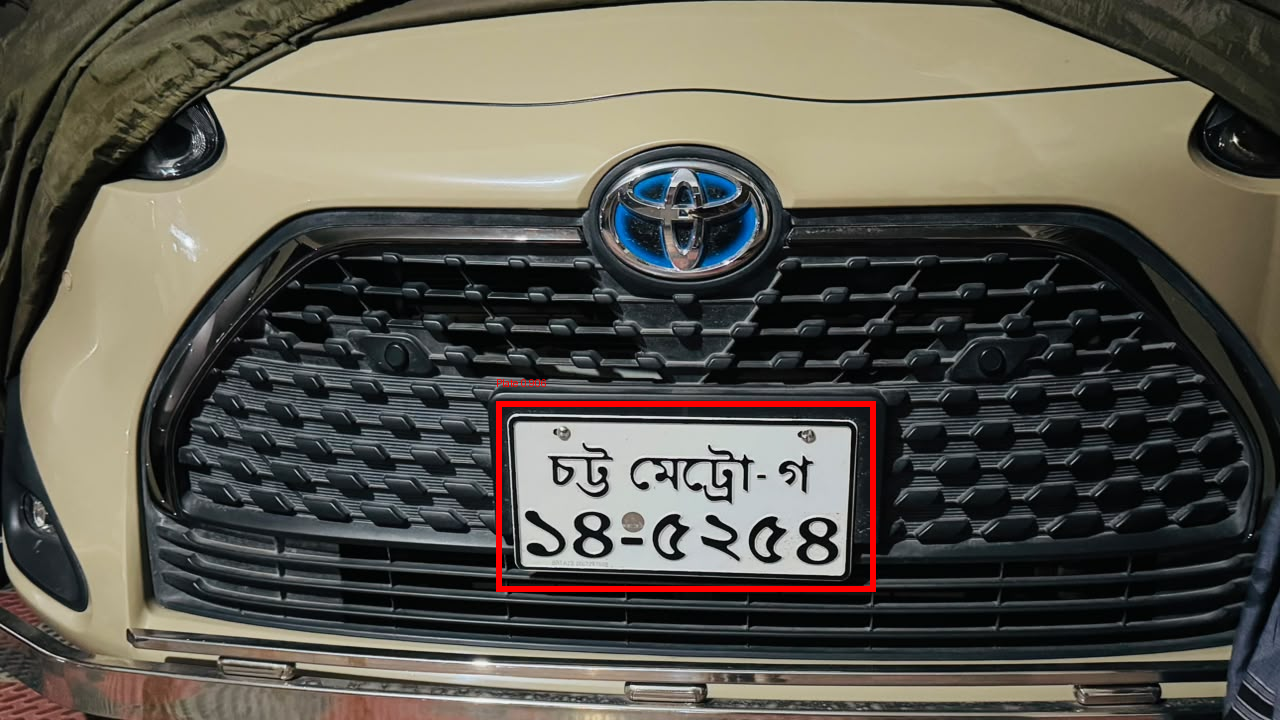

In [2]:
import sys
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from final_pipeline.lpr_pipeline import BangladeshLPR

image_path = project_root / "inference_tests" / "final_local_unseen_test" / "unseen_vehicle.jpg"

lpr = BangladeshLPR(
    str(project_root / "models" / "localization" / "localization_best.pt"),
    str(project_root / "models" / "character" / "character_best.pt")
)

result = lpr.recognize(str(image_path))

image = Image.open(image_path).convert("RGB")
draw = ImageDraw.Draw(image)

detections = result.get("localization_detections", [])

if detections:
    best = max(detections, key=lambda d: d["confidence"])
    x1, y1, x2, y2 = best["box"]
    confidence = best["confidence"]

    draw.rectangle(
        [x1, y1, x2, y2],
        outline="red",
        width=6
    )

    draw.text(
        (x1, max(0, y1 - 25)),
        f"Plate {confidence:.3f}",
        fill="red"
    )

print("=== FINAL LOCAL UNSEEN TEST ===")
print("Status:", result.get("status"))
print("Recognized Plate:")
print(result.get("text"))
print("Characters detected:", len(result.get("characters", [])))

if detections:
    print(f"Localization confidence: {confidence:.4f}")

display(image)

Selected image: C:\Users\HP\Downloads\unseen_vehicle_01.jpg

=== FINAL LOCAL UNSEEN TEST ===
Status: success

Recognized Plate:
chattogram metro ha
110831

Plate box: [441, 547, 810, 700]
Characters detected: 9
Localization confidence: 0.8883

Character detections:
chattogram 0.9420
1 0.8912
8 0.8898
1 0.8891
metro 0.8820
1 0.8817
0 0.8771
3 0.8716
ha 0.5998

=== DETECTION IMAGE ===


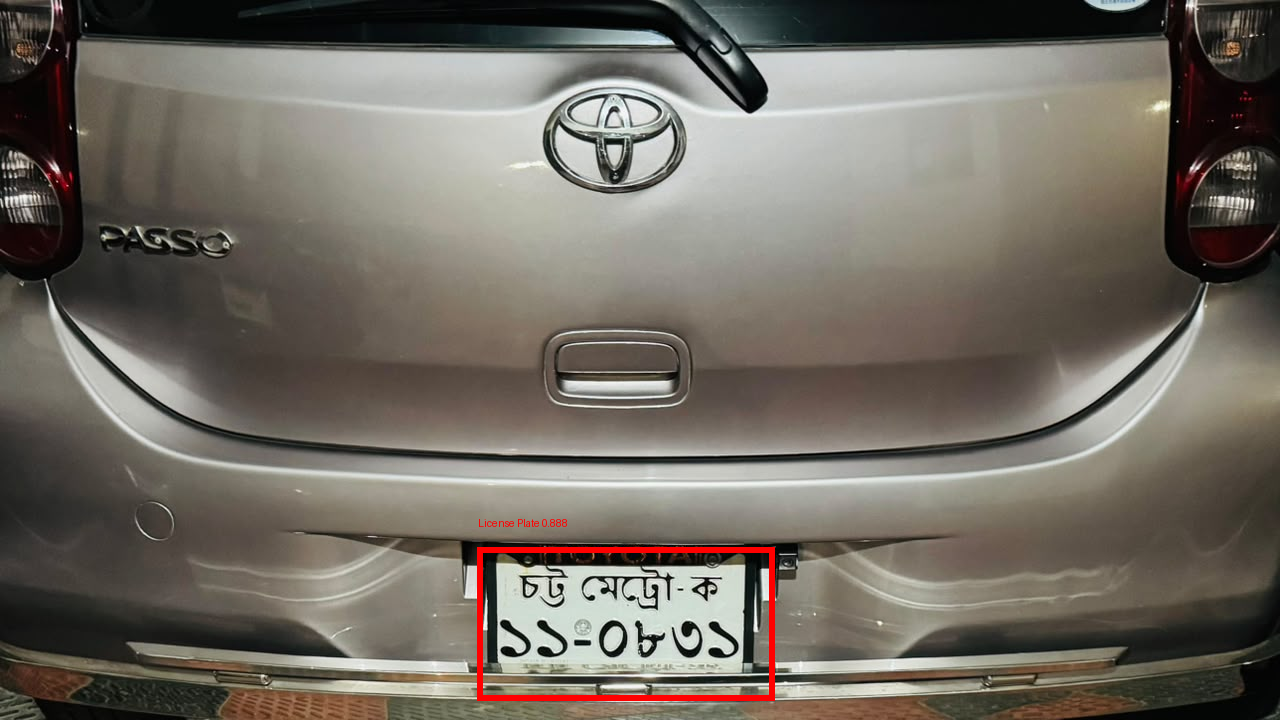

In [ ]:
import sys
from pathlib import Path
from tkinter import Tk, filedialog
from PIL import Image, ImageDraw
from IPython.display import display

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from final_pipeline.lpr_pipeline import BangladeshLPR

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

selected_file = filedialog.askopenfilename(
    title="Select a New Unseen Vehicle Image",
    filetypes=[
        ("Image Files", "*.jpg *.jpeg *.png *.jfif"),
        ("All Files", "*.*")
    ]
)

root.destroy()

if not selected_file:
    raise ValueError("No image selected.")

image_path = Path(selected_file)

print("Selected image:", image_path)

lpr = BangladeshLPR(
    str(project_root / "models" / "localization" / "localization_best.pt"),
    str(project_root / "models" / "character" / "character_best.pt")
)

result = lpr.recognize(str(image_path))

image = Image.open(image_path).convert("RGB")
draw = ImageDraw.Draw(image)

detections = result.get("localization_detections", [])

if detections:
    best = max(detections, key=lambda d: d["confidence"])

    x1, y1, x2, y2 = best["box"]
    confidence = best["confidence"]

    draw.rectangle(
        [x1, y1, x2, y2],
        outline="red",
        width=6
    )

    draw.text(
        (x1, max(0, y1 - 30)),
        f"License Plate {confidence:.3f}",
        fill="red"
    )

print("\n=== FINAL LOCAL UNSEEN TEST ===")
print("Status:", result.get("status"))

print("\nRecognized Plate:")
print(result.get("text"))

print("\nPlate box:", result.get("plate_box"))
print("Characters detected:", len(result.get("characters", [])))

if detections:
    print(f"Localization confidence: {confidence:.4f}")
else:
    print("Localization confidence: No plate detected")

print("\nCharacter detections:")
for character in result.get("characters", []):
    print(
        character["label"],
        f"{character['confidence']:.4f}"
    )

print("\n=== DETECTION IMAGE ===")
display(image)

=== FINAL LOCAL UNSEEN TEST ===
Status: success

Recognized Plate:
chattogram metro ga
145254

Characters detected: 9
Localization confidence: 0.9065

=== DETECTION IMAGE ===


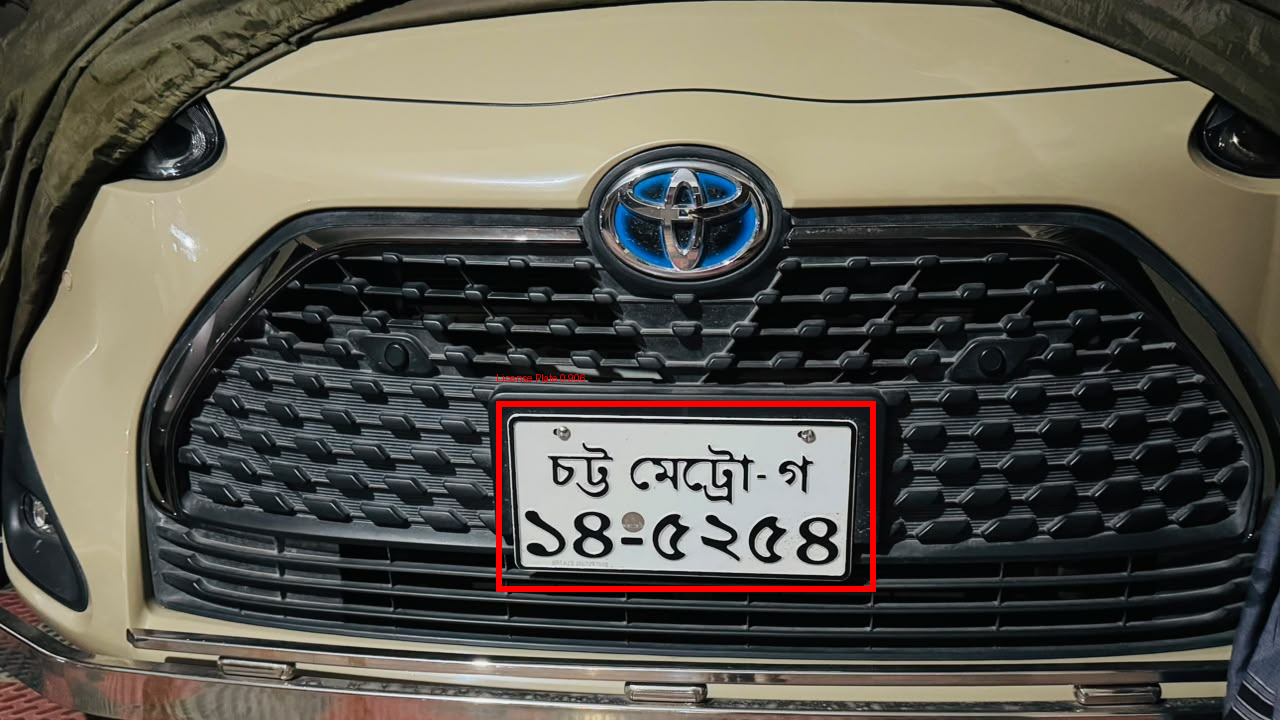

In [2]:
import sys
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from final_pipeline.lpr_pipeline import BangladeshLPR

image_path = (
    project_root
    / "inference_tests"
    / "final_local_unseen_test"
    / "unseen_vehicle.jpg"
)

lpr = BangladeshLPR(
    str(project_root / "models" / "localization" / "localization_best.pt"),
    str(project_root / "models" / "character" / "character_best.pt")
)

result = lpr.recognize(str(image_path))

image = Image.open(image_path).convert("RGB")
draw = ImageDraw.Draw(image)

detections = result.get("localization_detections", [])

if detections:
    best = max(detections, key=lambda d: d["confidence"])

    x1, y1, x2, y2 = best["box"]
    confidence = best["confidence"]

    draw.rectangle(
        [x1, y1, x2, y2],
        outline="red",
        width=6
    )

    draw.text(
        (x1, max(0, y1 - 30)),
        f"License Plate {confidence:.3f}",
        fill="red"
    )

print("=== FINAL LOCAL UNSEEN TEST ===")
print("Status:", result.get("status"))

print("\nRecognized Plate:")
print(result.get("text"))

print("\nCharacters detected:", len(result.get("characters", [])))

if detections:
    print(f"Localization confidence: {confidence:.4f}")
else:
    print("Localization confidence: No plate detected")

print("\n=== DETECTION IMAGE ===")

display(image)

In [ ]:
import sys
import io
from pathlib import Path

import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image, ImageDraw

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from final_pipeline.lpr_pipeline import BangladeshLPR

lpr = BangladeshLPR(
    str(project_root / "models" / "localization" / "localization_best.pt"),
    str(project_root / "models" / "character" / "character_best.pt")
)

upload = widgets.FileUpload(
    accept=".jpg,.jpeg,.png,.jfif",
    multiple=False,
    description="Upload Image"
)

output = widgets.Output()


def process_image(change):
    global result
    if not upload.value:
        return

    uploaded = upload.value[0]

    file_name = uploaded["name"]
    file_data = bytes(uploaded["content"])

    test_dir = (
        project_root
        / "inference_tests"
        / "final_local_unseen_test"
    )
    test_dir.mkdir(parents=True, exist_ok=True)

    image_path = test_dir / file_name

    with open(image_path, "wb") as f:
        f.write(file_data)

    with output:
        clear_output(wait=True)

        print("Processing:", file_name)
        print("Please wait...\n")

        result = lpr.recognize(str(image_path))

        original = Image.open(io.BytesIO(file_data)).convert("RGB")
        detected = original.copy()

        draw = ImageDraw.Draw(detected)

        detections = result.get("localization_detections", [])

        if detections:
            best = max(
                detections,
                key=lambda d: d["confidence"]
            )

            x1, y1, x2, y2 = best["box"]
            confidence = best["confidence"]

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=max(4, original.width // 250)
            )

            draw.text(
                (x1, max(0, y1 - 30)),
                f"Plate {confidence:.3f}",
                fill="red"
            )

        print("=== FINAL LPR RESULT ===")
        print("Status:", result.get("status"))

        print("\nRecognized Plate:")
        print(result.get("text"))

        print(
            "\nCharacters detected:",
            len(result.get("characters", []))
        )

        if detections:
            print(
                "Localization confidence:",
                f"{confidence:.4f}"
            )
        else:
            print("Localization confidence: No plate detected")

        print("\n=== ORIGINAL IMAGE ===")
        display(original)

        print("\n=== DETECTED IMAGE ===")
        display(detected)

        crop = result.get("crop")

        if crop is not None:
            print("\n=== LOCALIZED PLATE CROP ===")

            if isinstance(crop, Image.Image):
                display(crop)
            else:
                display(Image.fromarray(crop))


upload.observe(
    process_image,
    names="value"
)

display(
    widgets.HTML(
        "<h3>Bangladesh License Plate Recognition</h3>"
        "<p>Upload an unseen vehicle image for testing.</p>"
    )
)

display(upload)
display(output)

HTML(value='<h3>Bangladesh License Plate Recognition</h3><p>Upload an unseen vehicle image for testing.</p>')

FileUpload(value=(), accept='.jpg,.jpeg,.png,.jfif', description='Upload Image')

Output()

In [8]:
print("=== PROBLEM IMAGE CHARACTER PREDICTIONS ===")

for c in result.get("characters", []):
    print(
        f"{c['label']:12s} "
        f"confidence={c['confidence']:.4f} "
        f"x={c['x']:.1f} "
        f"y={c['y']:.1f}"
    )

=== PROBLEM IMAGE CHARACTER PREDICTIONS ===
chattogram   confidence=0.9420 x=103.0 y=40.6
1            confidence=0.8912 x=74.4 y=91.9
8            confidence=0.8898 x=208.5 y=93.9
1            confidence=0.8891 x=111.2 y=92.6
metro        confidence=0.8820 x=186.3 y=42.2
1            confidence=0.8817 x=282.7 y=93.5
0            confidence=0.8771 x=172.4 y=92.4
3            confidence=0.8716 x=246.2 y=93.3
ha           confidence=0.5998 x=266.1 y=42.1


In [6]:
print("=== ALL CHARACTER PREDICTIONS ===")

for c in result.get("characters", []):
    print(
        f"{c['label']:12s} "
        f"confidence={c['confidence']:.4f} "
        f"x={c['x']:.1f} "
        f"y={c['y']:.1f}"
    )

=== ALL CHARACTER PREDICTIONS ===
chattogram   confidence=0.9445 x=130.7 y=69.0
metro        confidence=0.9044 x=241.6 y=74.2
5            confidence=0.8962 x=221.4 y=137.3
4            confidence=0.8932 x=368.2 y=140.3
4            confidence=0.8922 x=143.9 y=134.2
2            confidence=0.8904 x=270.0 y=139.8
1            confidence=0.8842 x=95.1 y=132.7
5            confidence=0.8798 x=318.4 y=138.8
ga           confidence=0.8660 x=348.0 y=75.0


In [9]:
from ultralytics import YOLO

char_model = YOLO(
    str(project_root / "models" / "character" / "character_best.pt")
)

crop = result["crop"]

raw_results = char_model.predict(
    source=crop,
    conf=0.01,
    iou=0.7,
    imgsz=640,
    verbose=False
)

print("=== LOW-CONFIDENCE CHARACTER CANDIDATES ===")

r = raw_results[0]

for box in r.boxes:
    cls_id = int(box.cls[0])
    label = char_model.names[cls_id]
    conf = float(box.conf[0])

    x1, y1, x2, y2 = box.xyxy[0].tolist()
    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2

    print(
        f"{label:12s} "
        f"confidence={conf:.4f} "
        f"x={cx:.1f} "
        f"y={cy:.1f}"
    )

=== LOW-CONFIDENCE CHARACTER CANDIDATES ===
chattogram   confidence=0.9470 x=103.3 y=40.7
1            confidence=0.8909 x=111.3 y=92.5
8            confidence=0.8894 x=208.6 y=94.1
metro        confidence=0.8894 x=186.4 y=42.1
1            confidence=0.8836 x=282.8 y=93.5
1            confidence=0.8834 x=74.5 y=92.2
0            confidence=0.8798 x=172.5 y=92.8
3            confidence=0.8727 x=246.4 y=93.5
ka           confidence=0.4635 x=265.9 y=41.6
ha           confidence=0.4104 x=266.2 y=42.1


In [10]:
import inspect
from final_pipeline.lpr_pipeline import BangladeshLPR

print(inspect.getsource(BangladeshLPR.recognize))

    def recognize(self, image_path):
        image = Image.open(image_path).convert("RGB")
        img_w, img_h = image.size

        loc_result = self.localization_model.predict(
            source=np.array(image),
            conf=0.05,
            iou=0.5,
            imgsz=640,
            device="cpu",
            verbose=False
        )[0]

        if len(loc_result.boxes) == 0:
            return {
                "status": "no_plate_detected",
                "text": None
            }

        detections = []

        for box in loc_result.boxes:
            confidence = float(box.conf[0])
            x1, y1, x2, y2 = map(
                float,
                box.xyxy[0].tolist()
            )

            detections.append({
                "box": [x1, y1, x2, y2],
                "confidence": confidence
            })

        merged_boxes = merge_boxes(
            [d["box"] for d in detections]
        )

        best_box = max(
            merged_boxes,
            key

In [11]:
import inspect

source = inspect.getsource(BangladeshLPR.recognize)
lines = source.splitlines()

for i, line in enumerate(lines):
    if "character_model" in line:
        start = max(0, i - 5)
        end = min(len(lines), i + 25)

        for j in range(start, end):
            print(f"{j+1:03d}: {lines[j]}")

050:         y2 = min(img_h, int(y2))
051: 
052:         plate_crop = image.crop((x1, y1, x2, y2))
053: 
054: 
055:         char_result = self.character_model.predict(
056:             source=np.array(plate_crop),
057:             conf=0.10,
058:             iou=0.5,
059:             imgsz=640,
060:             device="cpu",
061:             verbose=False
062:         )[0]
063: 
064:         characters = []
065: 
066:         for box in char_result.boxes:
067:             cls_id = int(box.cls[0])
068:             confidence = float(box.conf[0])
069: 
070:             cx, cy, w, h = map(
071:                 float,
072:                 box.xywh[0].tolist()
073:             )
074: 
075:             characters.append({
076:                 "label": self.character_model.names[cls_id],
077:                 "confidence": confidence,
078:                 "x": cx,
079:                 "y": cy,
071:                 float,
072:                 box.xywh[0].tolist()
073:             )
074: 
075:  

In [12]:
print("=== CHARACTER CONFIDENCE TEST ===")

for test_conf in [0.10, 0.05, 0.01]:
    test_result = char_model.predict(
        source=result["crop"],
        conf=test_conf,
        iou=0.5,
        imgsz=640,
        device="cpu",
        verbose=False
    )[0]

    print(f"\n--- conf={test_conf} ---")

    for box in test_result.boxes:
        cls_id = int(box.cls[0])
        label = char_model.names[cls_id]
        confidence = float(box.conf[0])

        cx, cy, w, h = map(float, box.xywh[0].tolist())

        if cy < 70:
            print(
                f"{label:12s} "
                f"confidence={confidence:.4f} "
                f"x={cx:.1f} "
                f"y={cy:.1f}"
            )

=== CHARACTER CONFIDENCE TEST ===

--- conf=0.1 ---
chattogram   confidence=0.9470 x=103.3 y=40.7
metro        confidence=0.8894 x=186.4 y=42.1
ka           confidence=0.4635 x=265.9 y=41.6
ha           confidence=0.4104 x=266.2 y=42.1

--- conf=0.05 ---
chattogram   confidence=0.9470 x=103.3 y=40.7
metro        confidence=0.8894 x=186.4 y=42.1
ka           confidence=0.4635 x=265.9 y=41.6
ha           confidence=0.4104 x=266.2 y=42.1

--- conf=0.01 ---
chattogram   confidence=0.9470 x=103.3 y=40.7
metro        confidence=0.8894 x=186.4 y=42.1
ka           confidence=0.4635 x=265.9 y=41.6
ha           confidence=0.4104 x=266.2 y=42.1


In [13]:
import inspect
from final_pipeline.lpr_pipeline import remove_character_duplicates

print(inspect.getsource(remove_character_duplicates))

def remove_character_duplicates(characters, distance_ratio=0.35):
    if not characters:
        return []

    chars = sorted(
        characters,
        key=lambda c: c["confidence"],
        reverse=True
    )

    kept = []

    for char in chars:
        duplicate = False

        for existing in kept:
            avg_width = (char["w"] + existing["w"]) / 2
            avg_height = (char["h"] + existing["h"]) / 2

            x_close = (
                abs(char["x"] - existing["x"])
                < avg_width * distance_ratio
            )

            y_close = (
                abs(char["y"] - existing["y"])
                < avg_height * distance_ratio
            )

            if x_close and y_close:
                duplicate = True
                break

        if not duplicate:
            kept.append(char)

    return kept



In [14]:
import inspect

source = inspect.getsource(BangladeshLPR.recognize)
lines = source.splitlines()

for i in range(30, 100):
    if i < len(lines):
        print(f"{i+1:03d}: {lines[i]}")

031:                 "confidence": confidence
032:             })
033: 
034:         merged_boxes = merge_boxes(
035:             [d["box"] for d in detections]
036:         )
037: 
038:         best_box = max(
039:             merged_boxes,
040:             key=lambda b: (b[2] - b[0]) * (b[3] - b[1])
041:         )
042: 
043:         x1, y1, x2, y2 = best_box
044: 
045:         padding = (x2 - x1) * 0.12
046: 
047:         x1 = max(0, int(x1 - padding))
048:         x2 = min(img_w, int(x2 + padding))
049:         y1 = max(0, int(y1))
050:         y2 = min(img_h, int(y2))
051: 
052:         plate_crop = image.crop((x1, y1, x2, y2))
053: 
054: 
055:         char_result = self.character_model.predict(
056:             source=np.array(plate_crop),
057:             conf=0.10,
058:             iou=0.5,
059:             imgsz=640,
060:             device="cpu",
061:             verbose=False
062:         )[0]
063: 
064:         characters = []
065: 
066:         for box in char_result.boxes:

In [15]:
import numpy as np

print("=== PIL vs NUMPY TEST ===")

for input_name, input_image in [
    ("PIL", result["crop"]),
    ("NUMPY", np.array(result["crop"]))
]:
    r = char_model.predict(
        source=input_image,
        conf=0.10,
        iou=0.5,
        imgsz=640,
        device="cpu",
        verbose=False
    )[0]

    print(f"\n--- {input_name} ---")

    for box in r.boxes:
        cls_id = int(box.cls[0])
        label = char_model.names[cls_id]
        confidence = float(box.conf[0])

        cx, cy, w, h = map(float, box.xywh[0].tolist())

        if cy < 70:
            print(
                f"{label:12s} "
                f"confidence={confidence:.4f} "
                f"x={cx:.1f} "
                f"y={cy:.1f}"
            )

=== PIL vs NUMPY TEST ===

--- PIL ---
chattogram   confidence=0.9470 x=103.3 y=40.7
metro        confidence=0.8894 x=186.4 y=42.1
ka           confidence=0.4635 x=265.9 y=41.6
ha           confidence=0.4104 x=266.2 y=42.1

--- NUMPY ---
chattogram   confidence=0.9420 x=103.0 y=40.6
metro        confidence=0.8820 x=186.3 y=42.2
ha           confidence=0.5998 x=266.1 y=42.1


In [ ]:
import sys
import io
from pathlib import Path

import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image, ImageDraw

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from final_pipeline.lpr_pipeline import BangladeshLPR

lpr = BangladeshLPR(
    str(project_root / "models" / "localization" / "localization_best.pt"),
    str(project_root / "models" / "character" / "character_best.pt")
)

upload = widgets.FileUpload(
    accept=".jpg,.jpeg,.png,.jfif",
    multiple=False,
    description="Upload Image"
)

output = widgets.Output()


def process_image(change):
    global result
    if not upload.value:
        return

    uploaded = upload.value[0]

    file_name = uploaded["name"]
    file_data = bytes(uploaded["content"])

    test_dir = (
        project_root
        / "inference_tests"
        / "final_local_unseen_test"
    )
    test_dir.mkdir(parents=True, exist_ok=True)

    image_path = test_dir / file_name

    with open(image_path, "wb") as f:
        f.write(file_data)

    with output:
        clear_output(wait=True)

        print("Processing:", file_name)
        print("Please wait...\n")

        result = lpr.recognize(str(image_path))

        original = Image.open(io.BytesIO(file_data)).convert("RGB")
        detected = original.copy()

        draw = ImageDraw.Draw(detected)

        detections = result.get("localization_detections", [])

        if detections:
            best = max(
                detections,
                key=lambda d: d["confidence"]
            )

            x1, y1, x2, y2 = best["box"]
            confidence = best["confidence"]

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=max(4, original.width // 250)
            )

            draw.text(
                (x1, max(0, y1 - 30)),
                f"Plate {confidence:.3f}",
                fill="red"
            )

        print("=== FINAL LPR RESULT ===")
        print("Status:", result.get("status"))

        print("\nRecognized Plate:")
        print(result.get("text"))

        print(
            "\nCharacters detected:",
            len(result.get("characters", []))
        )

        if detections:
            print(
                "Localization confidence:",
                f"{confidence:.4f}"
            )
        else:
            print("Localization confidence: No plate detected")

        print("\n=== ORIGINAL IMAGE ===")
        display(original)

        print("\n=== DETECTED IMAGE ===")
        display(detected)

        crop = result.get("crop")

        if crop is not None:
            print("\n=== LOCALIZED PLATE CROP ===")

            if isinstance(crop, Image.Image):
                display(crop)
            else:
                display(Image.fromarray(crop))


upload.observe(
    process_image,
    names="value"
)

display(
    widgets.HTML(
        "<h3>Bangladesh License Plate Recognition</h3>"
        "<p>Upload an unseen vehicle image for testing.</p>"
    )
)

display(upload)
display(output)

HTML(value='<h3>Bangladesh License Plate Recognition</h3><p>Upload an unseen vehicle image for testing.</p>')

FileUpload(value=(), accept='.jpg,.jpeg,.png,.jfif', description='Upload Image')

Output()